In [17]:
!nvidia-smi

Thu Oct 29 11:30:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce GTX 1650 Ti     Off |   00000000:01:00.0 Off |                  N/A |
| N/A   51C    P8              3W /   50W |       9MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [18]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.14.1+cu126
True
NVIDIA GeForce GTX 1650 Ti


In [19]:
import torchvision, numpy, cv2
print("torchvision:", torchvision.__version__)
print("numpy:", numpy.__version__)
print("opencv:", cv2.__version__)

torchvision: 0.29.1+cu126
numpy: 2.5.3
opencv: 5.0.0


In [20]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ashfakyeafi/road-vehicle-images-dataset")

print("Path to dataset files:", path)

Path to dataset files: /home/youssef/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2


In [21]:
import os
from pathlib import Path
p = Path(path)
print(os.listdir(path))
print(os.listdir(p))


['trafic_data']
['trafic_data']


In [22]:
root = p / "trafic_data"

for folder, subfolders, files in os.walk(root):
    print(folder, "==>", len(files))

/home/youssef/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data ==> 1
/home/youssef/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/train ==> 1
/home/youssef/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/train/images ==> 2704
/home/youssef/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/train/labels ==> 2704
/home/youssef/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/valid ==> 1
/home/youssef/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/valid/images ==> 300
/home/youssef/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/valid/labels ==> 300


In [23]:
yaml_files = list(root.rglob("*.yaml"))
print(open(yaml_files[0]).read())

train: ../train/images
val: ../valid/images

nc: 21
names: ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']


In [24]:
images_dir = root / "train" / "images"
labels_dir = root / "train" / "labels"

name = os.listdir(images_dir)[0]

label = labels_dir / (Path(name).stem + '.txt')

content = open(label).read().splitlines()
print(content)
print(len(content))

['4 0.9 0.5638888888888889 0.1984375 0.2222222222222222', '4 0.6328125 0.5305555555555556 0.071875 0.11388888888888889', '12 0.78125 0.5611111111111111 0.015625 0.030555555555555555', '15 0.715625 0.5555555555555556 0.0125 0.022222222222222223', '4 0.1828125 0.49166666666666664 0.1328125 0.06388888888888888']
5


size: (640, 360)
mode: RGB


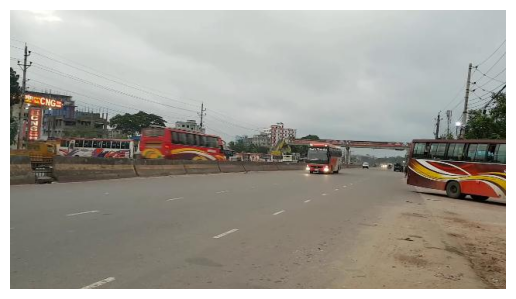

In [25]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(images_dir / name)
print(f"size: {img.size}")
print(f"mode: {img.mode}")

plt.imshow(img)
plt.axis("off")
plt.show()



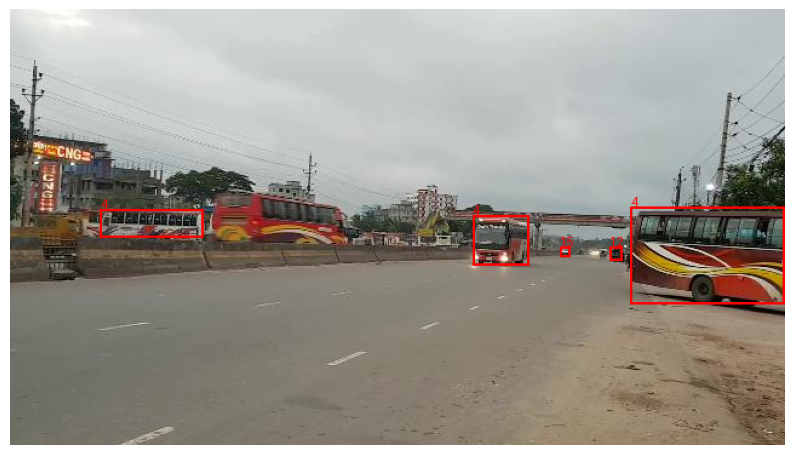

In [26]:
from PIL import ImageDraw

img_boxes = img.copy()

draw = ImageDraw.Draw(img_boxes)

W, H = img.size

for line in content:

    if line.strip() != "":

        parts = line.split()

        class_id = parts[0]
        x_center = float(parts[1])
        y_center = float(parts[2])
        width = float(parts[3])
        height = float(parts[4])

        x_center = x_center * W
        y_center = y_center * H
        width = width * W
        height = height * H

        x1 = x_center - width / 2
        y1 = y_center - height / 2
        x2 = x_center + width / 2
        y2 = y_center + height / 2

        draw.rectangle([x1, y1, x2, y2], outline="red", width=2)
        draw.text((x1, y1 - 10), class_id, fill="red")

plt.figure(figsize=(10, 6))
plt.imshow(img_boxes)
plt.axis("off")
plt.show()

In [ ]:
import yaml

with open(yaml_files[0]) as f:
    data = yaml.safe_load(f)

names = data["names"]
nc = data["nc"]

print("nc:", nc)
print("number of names:", len(names))
for i in range(len(names)):
    print(i, names[i])


nc: 21
number of names: 21
0 ambulance
1 army vehicle
2 auto rickshaw
3 bicycle
4 bus
5 car
6 garbagevan
7 human hauler
8 minibus
9 minivan
10 motorbike
11 pickup
12 policecar
13 rickshaw
14 scooter
15 suv
16 taxi
17 three wheelers -CNG-
18 truck
19 van
20 wheelbarrow


21

In [29]:
def is_valid_line(line):
    parts = line.split()

    if len(parts) != 5:
        return False

    try:
        class_id = int(float(parts[0]))
        x_c = float(parts[1])
        y_c = float(parts[2])
        w = float(parts[3])
        h = float(parts[4])
    except ValueError:
        return False

    if class_id < 0 or class_id >= nc:
        return False
    if x_c < 0 or x_c > 1 or y_c < 0 or y_c > 1:
        return False
    if w <= 0 or w > 1 or h <= 0 or h > 1:
        return False

    return True

In [30]:
import shutil

clean_root = Path("../data/clean")

for split in ["train", "valid"]:

    # where we read
    images_dir = root / split / "images"
    labels_dir = root / split / "labels"

    # where we write (created if it doesn't exist)
    out_images = clean_root / split / "images"
    out_labels = clean_root / split / "labels"
    out_images.mkdir(parents=True, exist_ok=True)
    out_labels.mkdir(parents=True, exist_ok=True)

    kept = 0
    removed = 0

    for img_file in images_dir.iterdir():

        # the label file with the same name
        txt = labels_dir / (img_file.stem + ".txt")

        # check 1: can the image be opened?
        image_ok = True
        try:
            Image.open(img_file).verify()
        except Exception:
            image_ok = False

        # check 2: does the label exist?
        label_ok = txt.exists()

        # check 3: keep only the valid lines
        good_lines = []
        if image_ok and label_ok:
            for line in open(txt).read().splitlines():
                if line.strip() != "" and is_valid_line(line):
                    good_lines.append(line)

        # decision
        if image_ok and label_ok and len(good_lines) > 0:
            # copy the image
            shutil.copy(img_file, out_images / img_file.name)
            # write the cleaned label
            f = open(out_labels / txt.name, "w")
            f.write("\n".join(good_lines))
            f.close()
            kept += 1
        else:
            print("Removed:", img_file.name)
            removed += 1

    print("=====", split, "=====")
    print("Kept:", kept)
    print("Removed:", removed)

Removed: 231_jpg.rf.42292592b7fed42abf94d9624eda3fa5.jpg
Removed: 01_jpg.rf.8d8a2f0f90d5b83893cd252acd832c93.jpg
===== train =====
Kept: 2702
Removed: 2
Removed: Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.jpg
Removed: Pias--360-_PNG.rf.8405b0e44009a9300e0a1100ccf7d5b3.jpg
===== valid =====
Kept: 298
Removed: 2


ambulance : 70
army vehicle : 43
auto rickshaw : 372
bicycle : 427
bus : 2909
car : 4632
garbagevan : 3
human hauler : 169
minibus : 93
minivan : 822
motorbike : 1949
pickup : 1083
policecar : 31
rickshaw : 3336
scooter : 37
suv : 798
taxi : 41
three wheelers -CNG- : 2734
truck : 1411
van : 693
wheelbarrow : 111


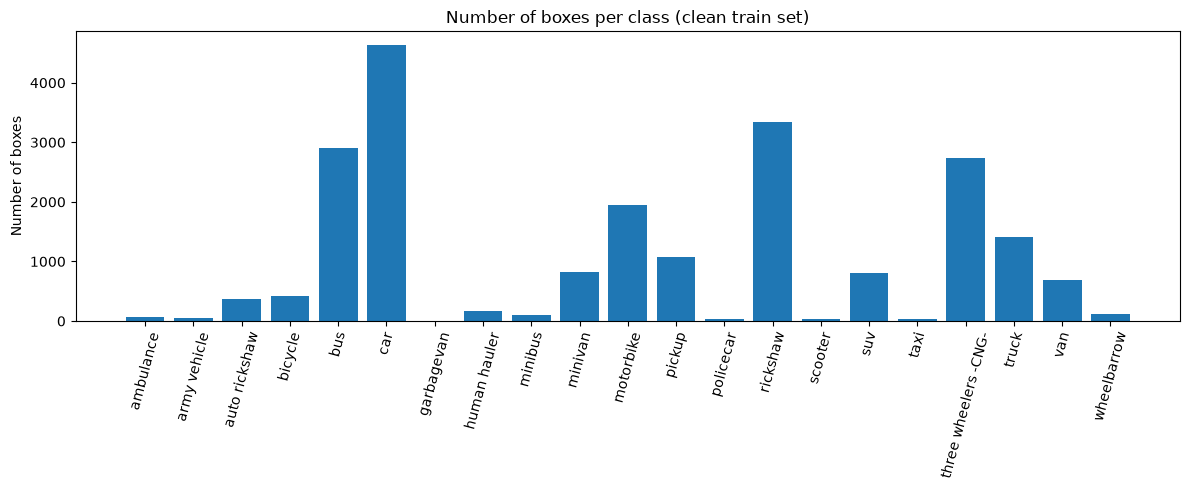

In [31]:
counts = [0] * nc

for txt in (clean_root / "train" / "labels").iterdir():
    for line in open(txt).read().splitlines():
        class_id = int(float(line.split()[0]))
        counts[class_id] += 1

for i in range(nc):
    print(names[i], ":", counts[i])

plt.figure(figsize=(12, 5))
plt.bar(names, counts)
plt.xticks(rotation=75)
plt.title("Number of boxes per class (clean train set)")
plt.ylabel("Number of boxes")
plt.tight_layout()
plt.show()

In [32]:
train_images = sorted(os.listdir(clean_root / "train" / "images"))
valid_images = sorted(os.listdir(clean_root / "valid" / "images"))

print("Clean train:", len(train_images))
print("Clean valid:", len(valid_images))

Clean train: 2702
Clean valid: 298


In [33]:
from sklearn.model_selection import train_test_split

final_train, final_test = train_test_split(
    train_images,
    test_size=405,
    random_state=42
)

print("Train:", len(final_train))
print("Test:", len(final_test))

Train: 2297
Test: 405


In [34]:
final_root = Path("../data/final")

splits = {
    "train": (final_train, "train"),
    "valid": (valid_images, "valid"),
    "test": (final_test, "train"),      # test images come from the clean train folder
}

for new_split in splits:
    image_list, source_split = splits[new_split]

    out_images = final_root / new_split / "images"
    out_labels = final_root / new_split / "labels"
    out_images.mkdir(parents=True, exist_ok=True)
    out_labels.mkdir(parents=True, exist_ok=True)

    for image_name in image_list:
        label_name = Path(image_name).stem + ".txt"

        shutil.copy(clean_root / source_split / "images" / image_name, out_images / image_name)
        shutil.copy(clean_root / source_split / "labels" / label_name, out_labels / label_name)

    print(new_split, "copied:", len(image_list))

train copied: 2297
valid copied: 298
test copied: 405


In [35]:
new_yaml = {
    "path": str(final_root.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": nc,
    "names": names,
}

with open(final_root / "data.yaml", "w") as f:
    yaml.dump(new_yaml, f, sort_keys=False)

print(open(final_root / "data.yaml").read())

path: /home/youssef/Desktop/youcode/viator/data/final
train: train/images
val: valid/images
test: test/images
nc: 21
names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow

